# Treasury Market Basket Analysis — 01: Classical Association Rules (Apriori)

**Purpose.** Implement the textbook support / confidence / lift association-rule
pipeline over treasury service adoption, with a hand-rolled Apriori frequent-itemset
generator for itemset sizes 1–3. This notebook is the *classical baseline* against which
the other approaches in this investigation are compared.

**Data source.** `PL_DATA_STUDIO.DERIVED.CORE_TREASURY_ACCOUNTS_MONTHLY`, pinned to
`VERSION_PARTITION = '2.5'` and `DATE_PARTITION = '2026-08-31'` (97 rows, 9 baskets,
11 services). Service-group names are absent from the fact table and are recovered via a
pre-deduplicated join to `PL_DATA_STUDIO.INTEGRATION_TESTING."TreasuryServices_Prod_7-1-26"`;
that dimension lives in an integration-testing schema, so **the group mapping is provisional**.
Both pinned partitions are mandatory — an unpinned query silently mixes versions `2.3` and `2.5`.

All loading and metric primitives come from `mba_common.py`; nothing here re-derives them.

---

## ⚠️ Read this before reading any number below

**This dataset is degenerate. The association metrics in this notebook are not business findings.**

- There are only **9 baskets**. Support is quantised to ninths; the smallest resolvable
  difference is **1/9 = 0.111**.
- **8 of the 9 baskets are byte-identical** (all 11 services). The single varying basket is
  **`OBX Integrated & Co.`**, which lacks both `Incoming Foreign` and `Outgoing Foreign`.
- Consequently **lift takes only two values in the entire dataset: `1.0` and `1.125`**
  (= 1 / 0.889). No other value is attainable at any itemset size.
- Nine of the eleven services are **universal** (present in every basket). Every "rule"
  among those nine is an arithmetic artifact of universal presence, not evidence of
  association: if A is in every basket, `confidence(X → A) = 1.0` for every X, trivially.
- At the `TREASURY_SERVICE_GROUP_NAME` grain the matrix is **fully degenerate**: all 3 groups
  appear in all 9 baskets, so every support, every confidence, and every lift is exactly
  `1.0`. We show that explicitly below rather than suppressing it.
- n = 9 cannot support an inference claim. A Fisher's exact test on the one available
  9-vs-8 split cannot reach p < 0.05.

**Therefore this notebook deliberately does not produce cross-sell recommendations.**
Its deliverable is *reusable, validated methodology* that will yield real results once
basket volume is materially higher. See the closing section for what is, and is not,
concludable from this snapshot.

---

## Metric definitions

For a rule *A → C* over *N* baskets, with `supp(X)` the fraction of baskets containing itemset *X*:

| Metric | Definition | Range | Reading |
|---|---|---|---|
| **Support** | `supp(A ∪ C)` | [0, 1] | How often the whole itemset occurs. Here quantised to 1/9. |
| **Confidence** | `supp(A ∪ C) / supp(A)` | [0, 1] | P(C given A). Directional. Trivially 1.0 whenever C is universal. |
| **Lift** | `supp(A ∪ C) / (supp(A)·supp(C))` | [0, ∞) | Ratio to independence. 1.0 = no association. Symmetric in A, C. |
| **Leverage** | `supp(A ∪ C) − supp(A)·supp(C)` | [−0.25, 0.25] | Additive excess over independence. 0 = no association. |
| **Conviction** | `(1 − supp(C)) / (1 − conf(A → C))` | [0, ∞] | Rule-violation odds ratio. `inf` when confidence is exactly 1.0. |

Lift = 1 and leverage = 0 both mean *independent*. Conviction `inf` means *no counterexample
basket exists*, which at N = 9 is weak evidence, not strong evidence.

In [1]:
# --- Import bootstrap: works locally and inside a Snowflake notebook -------------
import sys
from pathlib import Path

try:
    import mba_common
except ModuleNotFoundError:
    _candidates = [
        Path.cwd(),
        Path.cwd() / "investigations" / "treasury_mba",
        Path("/home/udf/notebook"),          # Snowflake notebook working dir
        Path("/tmp/notebook"),
        Path("include"),                      # common stage mount
    ]
    for _p in _candidates:
        if (_p / "mba_common.py").is_file() and str(_p) not in sys.path:
            sys.path.insert(0, str(_p))
    try:
        import mba_common
    except ModuleNotFoundError as exc:
        raise ModuleNotFoundError(
            "mba_common.py was not found on sys.path. It must be uploaded "
            "alongside this notebook (same stage directory / same folder). "
            f"Searched: {[str(p) for p in _candidates]}"
        ) from exc

print("mba_common loaded from", mba_common.__file__)

mba_common loaded from /Users/jeisenman/ra/qtwo_bench/src/workspaces/data_engineering/investigations/treasury_mba/mba_common.py


In [2]:
# ============================== PARAMETERS ==============================
VERSION_PARTITION = "2.5"            # pinned fact-table version
DATE_PARTITION    = "2026-08-31"     # pinned snapshot date
MIN_SUPPORT       = 1 / 9            # Apriori threshold; 1/9 = one basket at N=9
ITEM_GRAIN        = mba_common.ITEM_SERVICE   # primary grain: TREASURY_SERVICE_NAME
ROLLUP_GRAIN      = mba_common.ITEM_GROUP     # documented rollup: service group
MAX_ITEMSET_SIZE  = 3                # Apriori runs k = 1, 2, 3
# ========================================================================
print(f"{VERSION_PARTITION=} {DATE_PARTITION=} {MIN_SUPPORT=:.4f} {ITEM_GRAIN=}")

VERSION_PARTITION='2.5' DATE_PARTITION='2026-08-31' MIN_SUPPORT=0.1111 ITEM_GRAIN='TREASURY_SERVICE_NAME'


In [3]:
import itertools
from typing import Iterable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

snapshot = mba_common.load_snapshot(
    version_partition=VERSION_PARTITION,
    date_partition=DATE_PARTITION,
)
baskets = snapshot.basket_matrix(ITEM_GRAIN)

print(f"rows={len(snapshot.rows)}  baskets={snapshot.n_baskets}  items={baskets.shape[1]}")
baskets.astype(int)

 pip install snowflake-connector-python[secure-local-storage]


Initiating login request with your identity provider. A browser window should have opened for you to complete the login. If you can't see it, check existing browser windows, or your OS settings. Press CTRL+C to abort and try again...
Going to open: https://q2e.okta.com/app/snowflake/exks4if2pmTALcyNL357/sso/saml?SAMLRequest=lZJBc9owEIX%2Fikc927INoVSDydBQJiQkhWB66E1YC9FgS0YrY%2Fj3lQ106CGZ6U0jvd3vrd4O7o9F7h3AoNQqIVEQEg9UpoVU24Ss0onfJx5argTPtYKEnADJ%2FXCAvMhLNqrsu3qDfQVoPddIIWseElIZxTRHiUzxApDZjC1HLzMWByHjiGCsw5FLiUDpWO%2FWlozSuq6DuhNos6VxGIY0%2FEadqpF8ITeI8nNGabTVmc6vJUc30weIiIbdBuEUjjDRJoN2rIRYUwHx5pdW36U6f8pn3PVZhOwxTef%2B%2FOcyJd7oOu%2BDVlgVYJZgDjKD1dvsbAmdp30M%2FtZqUSFEASpdb3K%2Bg0wXZWVdw8Cd6AYEzfVWuo%2BbjhNS7qRY%2FMDF5GkV8c2i3neWldg%2B6h5fP63FM1aZujvYZ1VmfYxnOiPer2vMcRPzFLGCqWrCte4qjHt%2BFPpRN41D1umyuB%2F0%2Bp3fxBu7cKXitq288RvoneWtMV6W9K9nCscdduUmLot0NMtOr7PO3VeKqGmTGzmvDmvhZvgf4w%2FobeFlAV9dAtPxXOcyOzXZFdx%2BHFAURO2NFP6mlTIouMxHQhhAdEHlua4fDHALl%2FDp8Ez9d9OHfwA%3D&RelayState=ver%3A

 pip install snowflake-connector-python[secure-local-storage]


rows=97  baskets=9  items=11


TREASURY_SERVICE_NAME,Checks Deposited,Debits,Incoming Domestic,Incoming Foreign,Items Deposited,Monthly Servicing,Outgoing Domestic,Outgoing Foreign,Retail Item,Wholesale Deposit,Wholesale Item
RELATIONSHIP_ID,,,,,,,,,,,
025d8b3e-d123-42a7-9a04-2e604484193c,1,1,1,0,1,1,1,0,1,1,1
257bd20b-c38f-4726-87ce-a4cc9ed0df58,1,1,1,1,1,1,1,1,1,1,1
38550f29-8fca-49f4-be49-56e0a7e7e8e0,1,1,1,1,1,1,1,1,1,1,1
47102bd7-e025-4f4c-9634-d5de8c27ee25,1,1,1,1,1,1,1,1,1,1,1
5cc9db33-b27c-48a8-b7d0-d69aa632f092,1,1,1,1,1,1,1,1,1,1,1
7638e194-7916-4fae-879c-22a95fbccc57,1,1,1,1,1,1,1,1,1,1,1
901ba45b-5481-4a03-86b8-67f961665011,1,1,1,1,1,1,1,1,1,1,1
9858122e-0494-4b9a-b5bf-45eea25773b2,1,1,1,1,1,1,1,1,1,1,1
e53e199b-ef9b-4bc6-b709-452bb6b52514,1,1,1,1,1,1,1,1,1,1,1


### Degeneracy check — run before any interpretation

`mba_common.degeneracy_report` summarises how much usable co-occurrence variation exists.
Read its output before reading anything else in this notebook.

In [4]:
report = mba_common.degeneracy_report(baskets)
for k, v in report.items():
    print(f"{k:>22}: {v}")

delta = mba_common.min_detectable_support_delta(snapshot.n_baskets)
print(f"\n{'min support delta':>22}: {delta:.4f}  (one basket out of {snapshot.n_baskets})")

n_universal = len(report["universal_items"])
print(f"{'universal items':>22}: {n_universal} of {baskets.shape[1]}")
print(f"{'distinct basket rows':>22}: {report['distinct_baskets']} of {snapshot.n_baskets}"
      "  <- 8 of 9 baskets are identical")

             n_baskets: 9
               n_items: 11
      distinct_baskets: 2
       universal_items: ['Checks Deposited', 'Debits', 'Incoming Domestic', 'Items Deposited', 'Monthly Servicing', 'Outgoing Domestic', 'Retail Item', 'Wholesale Deposit', 'Wholesale Item']
  distinct_lift_values: [1.0, 1.125]
         is_degenerate: False
               verdict: near-degenerate: only 2 distinct basket signatures, so any 'pattern' restates a single deviating basket

     min support delta: 0.1111  (one basket out of 9)
       universal items: 9 of 11
  distinct basket rows: 2 of 9  <- 8 of 9 baskets are identical


In [5]:
# Which basket deviates, and how? (The entire signal in this dataset.)
sizes = baskets.sum(axis=1).rename("n_services")
names = (snapshot.rows[[mba_common.BASKET_KEY, "RELATIONSHIP_NAME"]]
         .drop_duplicates().set_index(mba_common.BASKET_KEY)["RELATIONSHIP_NAME"])
profile = pd.concat([names, sizes], axis=1).sort_values("n_services")
profile["missing_services"] = [
    ", ".join(baskets.columns[~baskets.loc[b]]) or "—" for b in profile.index
]
profile

,RELATIONSHIP_NAME,n_services,missing_services
RELATIONSHIP_ID,,,
025d8b3e-d123-42a7-9a04-2e604484193c,OBX Integrated & Co.,9,"Incoming Foreign, Outgoing Foreign"
38550f29-8fca-49f4-be49-56e0a7e7e8e0,Coastal Realty & Co.,11,—
e53e199b-ef9b-4bc6-b709-452bb6b52514,Currituck Properties,11,—
5cc9db33-b27c-48a8-b7d0-d69aa632f092,Acme Supply Inc. - Integrated,11,—
901ba45b-5481-4a03-86b8-67f961665011,Cape Lookout Marine,11,—
9858122e-0494-4b9a-b5bf-45eea25773b2,Cape Lookout Marine V3,11,—
47102bd7-e025-4f4c-9634-d5de8c27ee25,Cape Lookout Marine V4,11,—
7638e194-7916-4fae-879c-22a95fbccc57,"Bohannon Development, LLC",11,—
257bd20b-c38f-4726-87ce-a4cc9ed0df58,Charles & Laura Design Studios,11,—


## Hand-rolled Apriori

`mlxtend` is not available in this environment (see `GROUND_TRUTH.md`), so frequent
itemsets are generated directly. The implementation is the standard breadth-first
algorithm: generate size-*k* candidates by joining frequent size-(*k*−1) itemsets, prune
any candidate with an infrequent subset (the downward-closure property), then count.

`min_support` is a parameter. At N = 9 the only meaningful thresholds are multiples of 1/9.

In [6]:
def apriori_frequent_itemsets(
    matrix: pd.DataFrame,
    min_support: float,
    max_len: int = 3,
) -> pd.DataFrame:
    """Frequent itemsets up to ``max_len`` via breadth-first Apriori.

    Args:
        matrix: Boolean basket x item incidence matrix.
        min_support: Inclusive support threshold in [0, 1].
        max_len: Largest itemset size to enumerate.

    Returns:
        Columns ``itemset`` (frozenset), ``size``, ``count``, ``support``,
        sorted by size then support descending.

    Raises:
        ValueError: If ``matrix`` is empty, ``min_support`` is outside [0, 1],
            or ``max_len`` < 1.
    """
    if matrix.empty:
        raise ValueError("basket matrix is empty")
    if not 0.0 <= min_support <= 1.0:
        raise ValueError(f"min_support must be in [0, 1], got {min_support!r}")
    if max_len < 1:
        raise ValueError(f"max_len must be >= 1, got {max_len!r}")

    n = len(matrix)
    items = list(matrix.columns)
    values = matrix.to_numpy(dtype=bool)
    col_of = {item: idx for idx, item in enumerate(items)}

    def support_of(itemset: frozenset) -> tuple[int, float]:
        mask = np.ones(n, dtype=bool)
        for item in itemset:
            mask &= values[:, col_of[item]]
        count = int(np.count_nonzero(mask))
        return count, count / n

    records: list[dict] = []
    frequent: list[frozenset] = []
    for item in items:
        candidate = frozenset((item,))
        count, support = support_of(candidate)
        if support >= min_support:
            frequent.append(candidate)
            records.append(
                {"itemset": candidate, "size": 1, "count": count, "support": support}
            )

    k = 2
    while frequent and k <= max_len:
        previous = set(frequent)
        candidates = {
            a | b
            for a, b in itertools.combinations(frequent, 2)
            if len(a | b) == k
        }
        # Downward closure: every (k-1)-subset must itself be frequent.
        candidates = {
            c for c in candidates
            if all(frozenset(s) in previous for s in itertools.combinations(c, k - 1))
        }
        frequent = []
        for candidate in sorted(candidates, key=lambda s: sorted(s)):
            count, support = support_of(candidate)
            if support >= min_support:
                frequent.append(candidate)
                records.append(
                    {"itemset": candidate, "size": k, "count": count,
                     "support": support}
                )
        k += 1

    if not records:
        return pd.DataFrame(columns=["itemset", "size", "count", "support"])
    return (pd.DataFrame(records)
            .sort_values(["size", "support"], ascending=[True, False],
                         ignore_index=True))


def label(itemset: Iterable[str]) -> str:
    """Render an itemset as a stable, sorted, comma-joined string."""
    return ", ".join(sorted(itemset))

In [7]:
itemsets = apriori_frequent_itemsets(baskets, MIN_SUPPORT, MAX_ITEMSET_SIZE)
itemsets["label"] = itemsets["itemset"].map(label)

print(f"min_support={MIN_SUPPORT:.4f}  frequent itemsets={len(itemsets)}")
print(itemsets.groupby("size").agg(
    n_itemsets=("itemset", "size"),
    min_support=("support", "min"),
    max_support=("support", "max"),
))
itemsets[["size", "label", "count", "support"]].head(20)

min_support=0.1111  frequent itemsets=231
      n_itemsets  min_support  max_support
size                                      
1             11       0.8889       1.0000
2             55       0.8889       1.0000
3            165       0.8889       1.0000


,size,label,count,support
0,1,Checks Deposited,9,1.0000
1,1,Debits,9,1.0000
2,1,Incoming Domestic,9,1.0000
3,1,Items Deposited,9,1.0000
4,1,Monthly Servicing,9,1.0000
5,1,Outgoing Domestic,9,1.0000
6,1,Retail Item,9,1.0000
7,1,Wholesale Deposit,9,1.0000
8,1,Wholesale Item,9,1.0000
9,1,Incoming Foreign,8,0.8889


### Full directional rule table

Every frequent itemset of size ≥ 2 is split into all non-empty, non-exhaustive
antecedent/consequent partitions, giving the complete *directional* rule set (unlike
`mba_common.pair_metrics`, which reports unordered pairs with both confidences side by side).
Metric definitions follow the table at the top of the notebook.

In [8]:
def association_rules(
    itemsets: pd.DataFrame,
    n_baskets: int,
    min_confidence: float = 0.0,
) -> pd.DataFrame:
    """Expand frequent itemsets into all directional rules with metrics.

    Args:
        itemsets: Output of :func:`apriori_frequent_itemsets`.
        n_baskets: Basket count, used only for the co-occurrence column.
        min_confidence: Inclusive confidence floor.

    Returns:
        One row per directional rule with support, confidence, lift, leverage
        and conviction, sorted by lift then confidence then support, descending.

    Raises:
        ValueError: If ``min_confidence`` is outside [0, 1].
    """
    if not 0.0 <= min_confidence <= 1.0:
        raise ValueError(f"min_confidence must be in [0, 1], got {min_confidence!r}")

    support = dict(zip(itemsets["itemset"], itemsets["support"]))
    records: list[dict] = []
    for whole, s_whole in support.items():
        if len(whole) < 2:
            continue
        for size in range(1, len(whole)):
            for antecedent in itertools.combinations(sorted(whole), size):
                a = frozenset(antecedent)
                c = whole - a
                s_a, s_c = support.get(a), support.get(c)
                if s_a is None or s_c is None:
                    continue  # consequent itemset below min_support
                confidence = s_whole / s_a
                if confidence < min_confidence:
                    continue
                records.append(
                    {
                        "antecedent": label(a),
                        "consequent": label(c),
                        "ant_size": len(a),
                        "con_size": len(c),
                        "cooccurrence": int(round(s_whole * n_baskets)),
                        "support": s_whole,
                        "support_antecedent": s_a,
                        "support_consequent": s_c,
                        "confidence": confidence,
                        "lift": s_whole / (s_a * s_c),
                        "leverage": s_whole - s_a * s_c,
                        "conviction": mba_common._conviction(s_c, confidence),
                    }
                )
    columns = ["antecedent", "consequent", "ant_size", "con_size", "cooccurrence",
               "support", "support_antecedent", "support_consequent",
               "confidence", "lift", "leverage", "conviction"]
    if not records:
        return pd.DataFrame(columns=columns)
    return (pd.DataFrame(records)[columns]
            .sort_values(["lift", "confidence", "support"],
                         ascending=False, ignore_index=True))

In [9]:
rules = association_rules(itemsets, snapshot.n_baskets)
print(f"directional rules: {len(rules)}")
print("\ndistinct lift values across ALL rules:",
      sorted(rules["lift"].round(6).unique()))
print("distinct leverage values:", sorted(rules["leverage"].round(6).unique()))
print("\nrules by (antecedent size, consequent size):")
print(rules.groupby(["ant_size", "con_size"]).size().rename("n_rules"))

directional rules: 1100

distinct lift values across ALL rules: [1.0, 1.125]
distinct leverage values: [0.0, 0.098765]

rules by (antecedent size, consequent size):
ant_size  con_size
1         1           110
          2           495
2         1           495
Name: n_rules, dtype: int64


In [10]:
# The only rules with lift != 1.0 -- all of them involve the two Foreign services.
# These are NOT findings: they restate that one basket lacks both Foreign services.
nontrivial = rules[rules["lift"].round(6) != 1.0]
print(f"rules with lift != 1.0: {len(nontrivial)} of {len(rules)}")
nontrivial.head(15)

rules with lift != 1.0: 38 of 1100


,antecedent,consequent,ant_size,con_size,cooccurrence,support,support_antecedent,support_consequent,confidence,lift,leverage,conviction
0,Incoming Foreign,Outgoing Foreign,1,1,8,0.8889,0.8889,0.8889,1.0000,1.1250,0.0988,inf
1,Outgoing Foreign,Incoming Foreign,1,1,8,0.8889,0.8889,0.8889,1.0000,1.1250,0.0988,inf
2,Incoming Foreign,"Checks Deposited, Outgoing Foreign",1,2,8,0.8889,0.8889,0.8889,1.0000,1.1250,0.0988,inf
3,Outgoing Foreign,"Checks Deposited, Incoming Foreign",1,2,8,0.8889,0.8889,0.8889,1.0000,1.1250,0.0988,inf
4,"Checks Deposited, Incoming Foreign",Outgoing Foreign,2,1,8,0.8889,0.8889,0.8889,1.0000,1.1250,0.0988,inf
5,"Checks Deposited, Outgoing Foreign",Incoming Foreign,2,1,8,0.8889,0.8889,0.8889,1.0000,1.1250,0.0988,inf
6,Incoming Foreign,"Debits, Outgoing Foreign",1,2,8,0.8889,0.8889,0.8889,1.0000,1.1250,0.0988,inf
7,Outgoing Foreign,"Debits, Incoming Foreign",1,2,8,0.8889,0.8889,0.8889,1.0000,1.1250,0.0988,inf
8,"Debits, Incoming Foreign",Outgoing Foreign,2,1,8,0.8889,0.8889,0.8889,1.0000,1.1250,0.0988,inf
9,"Debits, Outgoing Foreign",Incoming Foreign,2,1,8,0.8889,0.8889,0.8889,1.0000,1.1250,0.0988,inf


In [11]:
# Cross-check the pairwise subset against mba_common.pair_metrics (shared primitive).
pairs = mba_common.pair_metrics(baskets, min_support=MIN_SUPPORT)
print(f"unordered pairs: {len(pairs)}  distinct lift: "
      f"{sorted(pairs['lift'].round(6).unique())}")

mine = (rules[(rules.ant_size == 1) & (rules.con_size == 1)]
        .assign(key=lambda d: [frozenset((a, c)) for a, c in
                               zip(d.antecedent, d.consequent)])
        .groupby("key")["lift"].first())
theirs = (pairs.assign(key=lambda d: [frozenset((a, c)) for a, c in
                                      zip(d.antecedent, d.consequent)])
          .set_index("key")["lift"])
aligned = mine.align(theirs, join="inner")
assert np.allclose(aligned[0].to_numpy(), aligned[1].to_numpy()), "lift mismatch"
print(f"OK: {len(aligned[0])} pairwise lifts agree with mba_common.pair_metrics")

unordered pairs: 55  distinct lift: [1.0, 1.125]
OK: 55 pairwise lifts agree with mba_common.pair_metrics


## Figure 1 — Item support with the 1/9 quantisation grid

Support cannot take a value off these gridlines. The visual point is the *coarseness*:
with 9 baskets there are only 10 attainable support values, and the observed data uses
exactly two of them.

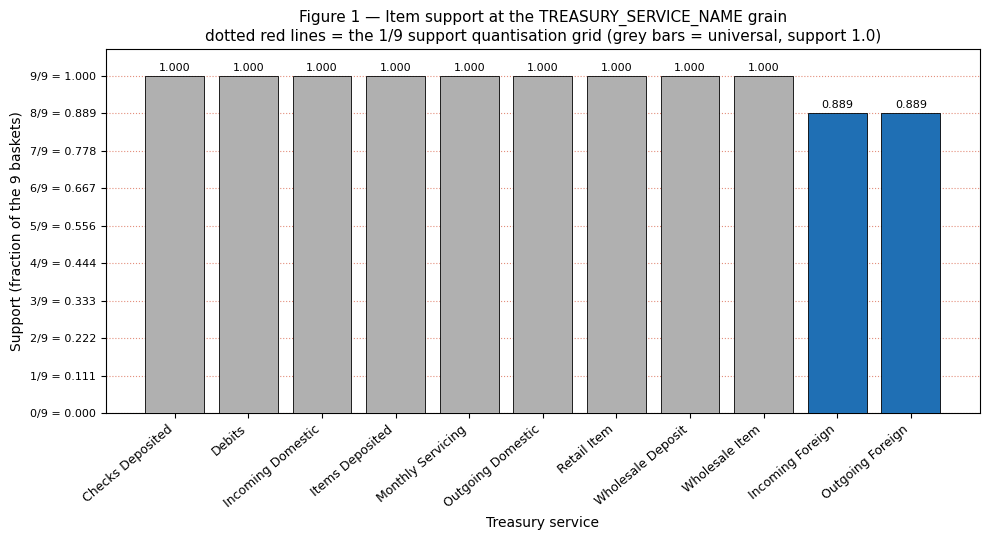

In [12]:
support = mba_common.item_support(baskets)
n = snapshot.n_baskets

fig, ax = plt.subplots(figsize=(10, 5.5))
colors = ["#b0b0b0" if v == 1.0 else "#1f6fb4" for v in support.to_numpy()]
ax.bar(range(len(support)), support.to_numpy(), color=colors,
       edgecolor="black", linewidth=0.6, zorder=3)
for k in range(n + 1):
    ax.axhline(k / n, color="#cc3311", linestyle=":", linewidth=0.8,
               alpha=0.55, zorder=1)
ax.set_xticks(range(len(support)))
ax.set_xticklabels(support.index, rotation=40, ha="right", fontsize=9)
ax.set_ylim(0, 1.08)
ax.set_yticks([k / n for k in range(n + 1)])
ax.set_yticklabels([f"{k}/9 = {k / n:.3f}" for k in range(n + 1)], fontsize=8)
ax.set_xlabel("Treasury service")
ax.set_ylabel("Support (fraction of the 9 baskets)")
ax.set_title("Figure 1 — Item support at the TREASURY_SERVICE_NAME grain\n"
             "dotted red lines = the 1/9 support quantisation grid "
             "(grey bars = universal, support 1.0)", fontsize=11)
for i, v in enumerate(support.to_numpy()):
    ax.text(i, v + 0.015, f"{v:.3f}", ha="center", fontsize=8, zorder=4)
fig.tight_layout()
plt.show()

## Figure 2 — Lift heatmap

Annotated because the matrix is only 11 × 11. Every off-diagonal cell is either `1.000`
(independent) or `1.125`; the `1.125` cells are confined to the two Foreign services.
A heatmap with two distinct values is the honest picture of this dataset.

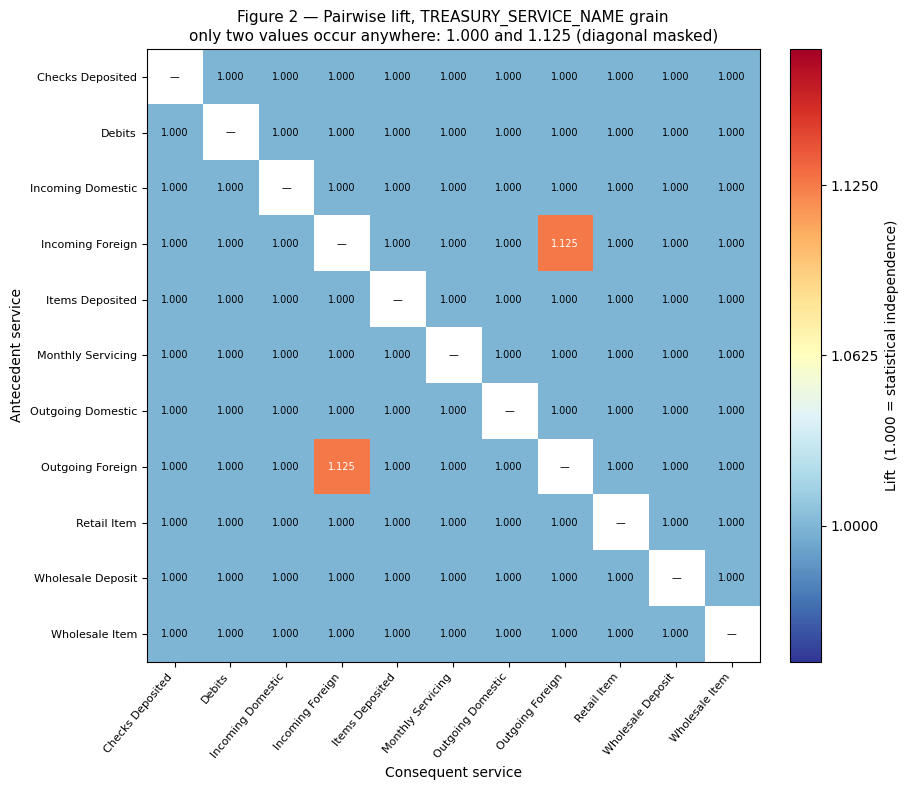

In [13]:
lifts = mba_common.lift_matrix(baskets)
items = list(lifts.columns)

fig, ax = plt.subplots(figsize=(9.5, 8))
image = ax.imshow(lifts.to_numpy(), cmap="RdYlBu_r", vmin=0.95, vmax=1.175)
bar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
bar.set_label("Lift  (1.000 = statistical independence)")
bar.set_ticks([1.0, 1.0625, 1.125])

ax.set_xticks(range(len(items)))
ax.set_yticks(range(len(items)))
ax.set_xticklabels(items, rotation=50, ha="right", fontsize=8)
ax.set_yticklabels(items, fontsize=8)
ax.set_xlabel("Consequent service")
ax.set_ylabel("Antecedent service")
ax.set_title("Figure 2 — Pairwise lift, TREASURY_SERVICE_NAME grain\n"
             "only two values occur anywhere: 1.000 and 1.125 "
             "(diagonal masked)", fontsize=11)
for i in range(len(items)):
    for j in range(len(items)):
        v = lifts.iat[i, j]
        ax.text(j, i, "—" if np.isnan(v) else f"{v:.3f}",
                ha="center", va="center", fontsize=7,
                color="black" if np.isnan(v) or v < 1.1 else "white")
fig.tight_layout()
plt.show()

## Figure 3 — Frequent-itemset counts vs `min_support`

Shows the Apriori threshold sweep. Because support is quantised to ninths, the counts are
piecewise constant: thresholds in (0, 0.889] all admit every service, and thresholds above
0.889 drop exactly the two Foreign services. The curve exercises the methodology; its
flatness is a property of this snapshot, not of the algorithm.

             k=1  k=2  k=3
min_support               
0.1111        11   55  165
0.3333        11   55  165
0.5556        11   55  165
0.7778        11   55  165
0.8889        11   55  165
1.0000         9   36   84


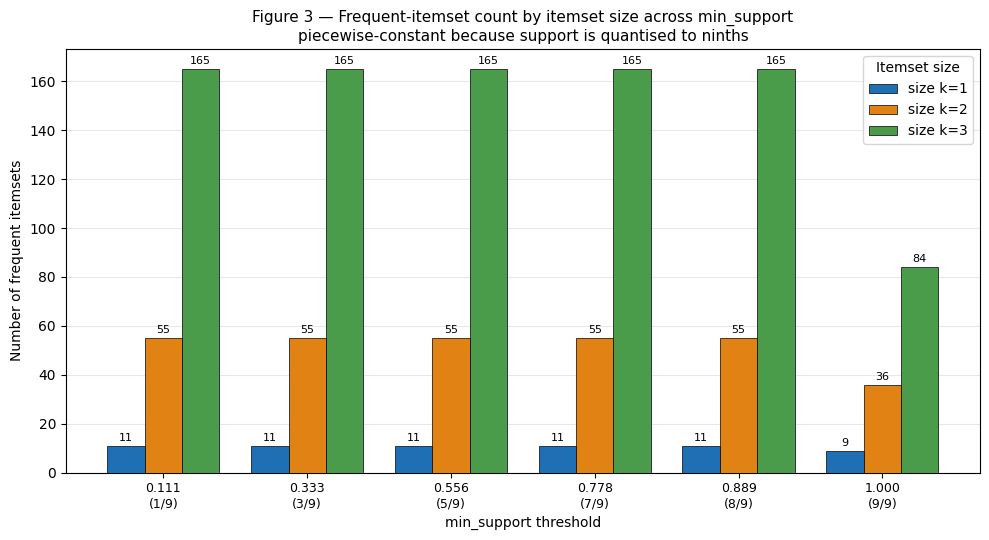

In [14]:
thresholds = [1 / 9, 3 / 9, 5 / 9, 7 / 9, 8 / 9, 1.0]
sweep = {}
for t in thresholds:
    found = apriori_frequent_itemsets(baskets, t, MAX_ITEMSET_SIZE)
    counts = found.groupby("size").size() if len(found) else pd.Series(dtype=int)
    sweep[t] = [int(counts.get(k, 0)) for k in range(1, MAX_ITEMSET_SIZE + 1)]
sweep_frame = pd.DataFrame(sweep, index=[f"k={k}" for k in
                                         range(1, MAX_ITEMSET_SIZE + 1)]).T
sweep_frame.index.name = "min_support"
print(sweep_frame)

fig, ax = plt.subplots(figsize=(10, 5.5))
width = 0.26
x = np.arange(len(thresholds))
palette = ["#1f6fb4", "#e08214", "#4a9b4a"]
for offset, (k, color) in enumerate(zip(range(1, MAX_ITEMSET_SIZE + 1), palette)):
    heights = [sweep[t][k - 1] for t in thresholds]
    bars = ax.bar(x + (offset - 1) * width, heights, width, label=f"size k={k}",
                  color=color, edgecolor="black", linewidth=0.5, zorder=3)
    ax.bar_label(bars, fontsize=8, padding=2)
ax.set_xticks(x)
ax.set_xticklabels([f"{t:.3f}\n({round(t * 9)}/9)" for t in thresholds], fontsize=9)
ax.set_xlabel("min_support threshold")
ax.set_ylabel("Number of frequent itemsets")
ax.set_title("Figure 3 — Frequent-itemset count by itemset size across min_support\n"
             "piecewise-constant because support is quantised to ninths", fontsize=11)
ax.legend(title="Itemset size")
ax.grid(axis="y", alpha=0.3, zorder=0)
fig.tight_layout()
plt.show()

## Figure 4 — Support vs confidence, lift encoded

The canonical association-rule diagnostic scatter. Here it collapses to three points
because support ∈ {0.889, 1.0} and confidence ∈ {0.889, 1.0}. Point size and colour both
encode lift. The collapse is the result.

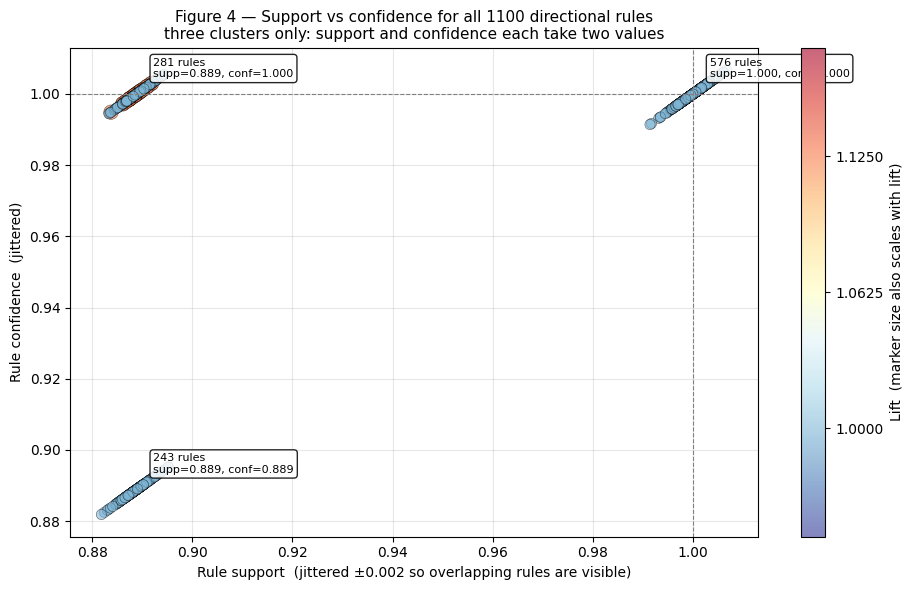

In [15]:
jitter = np.random.default_rng(0).normal(0, 0.0022, len(rules))

fig, ax = plt.subplots(figsize=(9.5, 6))
scatter = ax.scatter(
    rules["support"] + jitter,
    rules["confidence"] + jitter,
    c=rules["lift"],
    s=30 + 420 * (rules["lift"] - rules["lift"].min() + 0.06),
    cmap="RdYlBu_r", vmin=0.95, vmax=1.175,
    alpha=0.6, edgecolor="black", linewidth=0.4,
)
bar = fig.colorbar(scatter, ax=ax)
bar.set_label("Lift  (marker size also scales with lift)")
bar.set_ticks([1.0, 1.0625, 1.125])
ax.axhline(1.0, color="grey", linestyle="--", linewidth=0.8)
ax.axvline(1.0, color="grey", linestyle="--", linewidth=0.8)
ax.set_xlabel("Rule support  (jittered ±0.002 so overlapping rules are visible)")
ax.set_ylabel("Rule confidence  (jittered)")
ax.set_title(f"Figure 4 — Support vs confidence for all {len(rules)} directional rules\n"
             "three clusters only: support and confidence each take two values",
             fontsize=11)
for s, c in sorted({(round(s, 4), round(c, 4)) for s, c
                    in zip(rules["support"], rules["confidence"])}):
    k = len(rules[(rules["support"].round(4) == s)
                  & (rules["confidence"].round(4) == c)])
    ax.annotate(f"{k} rules\nsupp={s:.3f}, conf={c:.3f}",
                (s, c), textcoords="offset points", xytext=(12, 12), fontsize=8,
                bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.85))
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Rollup grain — `TREASURY_SERVICE_GROUP_NAME`

Reported as a **documented rollup**, not as a second independent result.

Two caveats carry over from `GROUND_TRUTH.md`: the column is 100% NULL in the fact table
and is recovered by join to an *integration-testing* dimension (so the mapping is
provisional), and the pre-deduplicated join is mandatory — joining the dimension raw
doubles the fact rows from 97 to 194.

At this grain all 3 groups appear in all 9 baskets, so the matrix is **fully degenerate**:
every support, confidence and lift is exactly `1.0`. We show this rather than hide it.

In [16]:
group_baskets = snapshot.basket_matrix(ROLLUP_GRAIN)
group_report = mba_common.degeneracy_report(group_baskets)
for k, v in group_report.items():
    print(f"{k:>22}: {v}")

group_itemsets = apriori_frequent_itemsets(group_baskets, MIN_SUPPORT, MAX_ITEMSET_SIZE)
group_itemsets["label"] = group_itemsets["itemset"].map(label)
group_rules = association_rules(group_itemsets, snapshot.n_baskets)

print(f"\ngroups: {list(group_baskets.columns)}")
print(f"frequent itemsets: {len(group_itemsets)}   directional rules: {len(group_rules)}")
print("distinct support :", sorted(group_rules['support'].round(6).unique()))
print("distinct confidence:", sorted(group_rules['confidence'].round(6).unique()))
print("distinct lift    :", sorted(group_rules['lift'].round(6).unique()))
print("distinct leverage:", sorted(group_rules['leverage'].round(6).unique()))

assert group_report["is_degenerate"], "group grain unexpectedly non-degenerate"
assert set(group_rules["lift"].round(6).unique()) == {1.0}
print("\nCONFIRMED: at the service-group grain every lift is exactly 1.0 — "
      "the rule table is a constant matrix and carries no information.")
group_rules[["antecedent", "consequent", "support", "confidence",
             "lift", "leverage", "conviction"]]

             n_baskets: 9
               n_items: 3
      distinct_baskets: 1
       universal_items: ['DDA', 'LockBox', 'Wire Transfer']
  distinct_lift_values: [1.0]
         is_degenerate: True
               verdict: fully degenerate: every lift identical, no method can find structure

groups: ['DDA', 'LockBox', 'Wire Transfer']
frequent itemsets: 7   directional rules: 12
distinct support : [1.0]
distinct confidence: [1.0]
distinct lift    : [1.0]
distinct leverage: [0.0]

CONFIRMED: at the service-group grain every lift is exactly 1.0 — the rule table is a constant matrix and carries no information.


,antecedent,consequent,support,confidence,lift,leverage,conviction
0,DDA,LockBox,1.0000,1.0000,1.0000,0.0000,inf
1,LockBox,DDA,1.0000,1.0000,1.0000,0.0000,inf
2,DDA,Wire Transfer,1.0000,1.0000,1.0000,0.0000,inf
3,Wire Transfer,DDA,1.0000,1.0000,1.0000,0.0000,inf
4,LockBox,Wire Transfer,1.0000,1.0000,1.0000,0.0000,inf
5,Wire Transfer,LockBox,1.0000,1.0000,1.0000,0.0000,inf
6,DDA,"LockBox, Wire Transfer",1.0000,1.0000,1.0000,0.0000,inf
7,LockBox,"DDA, Wire Transfer",1.0000,1.0000,1.0000,0.0000,inf
8,Wire Transfer,"DDA, LockBox",1.0000,1.0000,1.0000,0.0000,inf
9,"DDA, LockBox",Wire Transfer,1.0000,1.0000,1.0000,0.0000,inf


## What this would show at scale

The pipeline above — pinned extract → basket matrix → Apriori (k = 1…3) → full directional
rule table with five metrics → four diagnostics — is complete and cross-validated against
`mba_common.pair_metrics`. It is grain-agnostic and threshold-parameterised, so it is
reusable as-is. With a materially larger basket count it would surface:

- **Real lift dispersion.** Support would stop being quantised to ninths, and Figure 2 would
  show a genuine spread rather than two values. Lift meaningfully above 1 would become
  readable as co-adoption and below 1 as substitution.
- **A usable `min_support` frontier.** Figure 3 would become a real decay curve, letting
  the threshold be tuned to the rule count an analyst can act on instead of being
  piecewise-constant.
- **Differentiated rules.** Figure 4 would populate the support–confidence plane, making the
  high-confidence / high-lift corner — the only corner worth acting on — identifiable.
- **Testable claims.** With adequate n, candidate rules could carry Fisher's exact or
  permutation p-values and multiple-comparison correction, which n = 9 cannot support.

Scale means **baskets**, not rows. Adding months or service codes to 9 relationships does
not help; the binding constraint is 9 distinct relationships, 8 of which are identical.

## What is NOT concludable from this snapshot

Stated explicitly so no downstream reader over-reads the tables above:

1. **No cross-sell recommendation is supported.** Nine of eleven services are in every
   basket; there is nothing to cross-sell and no basket to target.
2. **No rule here is evidence of association.** `confidence(X → A) = 1.0` for every
   universal A is arithmetic, not behaviour.
3. **The `1.125` lifts are not a finding.** They restate a single fact — `OBX Integrated & Co.`
   lacks both Foreign services — in 1-, 2- and 3-itemset form. The `Incoming Foreign` ↔
   `Outgoing Foreign` pair is perfect (8/8, Jaccard 1.0), but one deviating basket cannot
   distinguish a product bundle from a data artifact.
4. **No statistical significance is claimable.** At n = 9 the one 9-vs-8 split cannot reach
   p < 0.05 under Fisher's exact; no amount of metric reporting changes that.
5. **Nothing is concludable at the service-group grain.** It is a constant matrix.
6. **Conviction `inf` is not strong evidence.** It means no counterexample basket exists
   among nine — consistent with both a real rule and pure chance.
7. **The group mapping itself is provisional**, sourced from `INTEGRATION_TESTING`.

The deliverable of this notebook is the validated method, not a result.